# 04 · Evaluación y comparación de modelos

**Problema:** clasificación binaria `Normal` vs. `Autoinmune` sobre el dataset limpio del proyecto.

Este notebook entrena y compara dos modelos:

- **Regresión Logística** como baseline simple e interpretable.
- **Random Forest** como modelo de ensamble no lineal.

La evaluación usa un split estratificado 80/20, validación cruzada de 5 folds para elegir el umbral de decisión y métricas adecuadas para clases desbalanceadas: Precision, Recall, F1, ROC-AUC y PR-AUC. Se excluye `Sickness_Duration_Months` porque separa los grupos por construcción y sería una fuga de información.


## Carga de datos y pipeline

El módulo `autoimmune_disorder_prediction.evaluation` concentra la carga, el preprocesamiento, el entrenamiento y las visualizaciones. El preprocesamiento incluye imputación, escalado de variables numéricas y codificación one-hot de variables categóricas.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from autoimmune_disorder_prediction.evaluation import (
    confusion_matrix_figure,
    evaluate_models,
    load_binary_data,
    precision_recall_curve_figure,
    results_table,
    roc_curve_figure,
    top_features,
)

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")

X, y = load_binary_data()
print(f"Filas: {len(X):,} | Variables: {X.shape[1]}")
print(f"Normal: {(y == 0).sum():,} | Autoinmune: {(y == 1).sum():,}")
print(f"Proporción de autoinmunes: {y.mean():.1%}")


Filas: 12,500 | Variables: 75
Normal: 2,500 | Autoinmune: 10,000
Proporción de autoinmunes: 80.0%


## Entrenamiento y métricas

Se entrenan ambos modelos con `class_weight="balanced"`. El umbral se elige con las probabilidades *out-of-fold* del conjunto de entrenamiento maximizando F1; después se evalúa una sola vez en el test. La tabla incluye métricas de test y de validación cruzada.


In [2]:
results = evaluate_models(X, y)
table = results_table(results)
display(table.round(4))


,Modelo,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,CV F1,CV ROC-AUC
0,Regresión Logística,0.8286,1.0000,1.0,1.0000,1.0000,1.0,1.0,1.0,1.0
1,Random Forest,0.8443,0.9996,1.0,0.9995,0.9997,1.0,1.0,1.0,1.0


**Lectura.** La Regresión Logística obtiene F1 = 1,0000 y no comete errores en test: 500 verdaderos negativos y 2.000 verdaderos positivos. El Random Forest obtiene F1 = 0,9997 porque comete un falso negativo (clasifica como `Normal` a un paciente autoinmune). Ambos modelos tienen ROC-AUC = 1,000 y PR-AUC = 1,000. La diferencia en F1 es mínima, pero el único error del Random Forest es el tipo de error más costoso en triaje.


## Matrices de confusión

La matriz desagrega los aciertos y errores. En la fila `Autoinmune`, un falso negativo es un paciente enfermo clasificado como sano; en la fila `Normal`, un falso positivo es una derivación innecesaria.


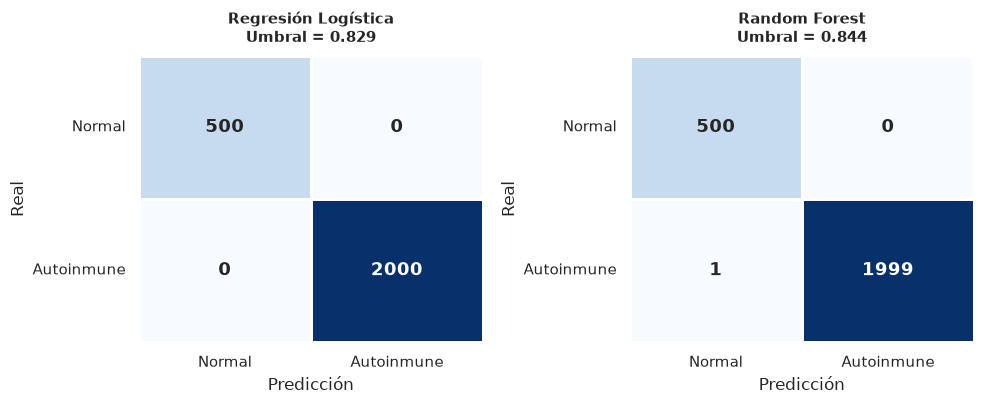

In [3]:
fig = confusion_matrix_figure(results)
plt.show()


## Curvas ROC

La curva ROC representa la tasa de verdaderos positivos (recall) frente a la tasa de falsos positivos al variar el umbral. El AUC resume la curva: 0,5 es azar y 1,0 es separación perfecta. Ambos modelos obtienen AUC = 1,000 y sus curvas se superponen. El AUC mide capacidad de ranking, no calibración ni utilidad clínica.


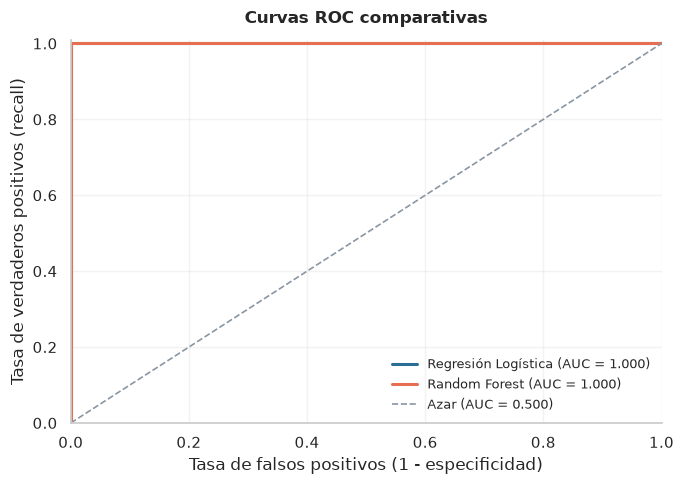

In [4]:
fig = roc_curve_figure(results)
plt.show()


## Curvas Precision-Recall

La curva Precision-Recall es más exigente con la clase positiva: muestra el compromiso entre recall y precision. El *Average Precision* (AP) resume el área. Ambos modelos obtienen AP = 1,000. La línea base es la proporción de positivos en el test (80%).


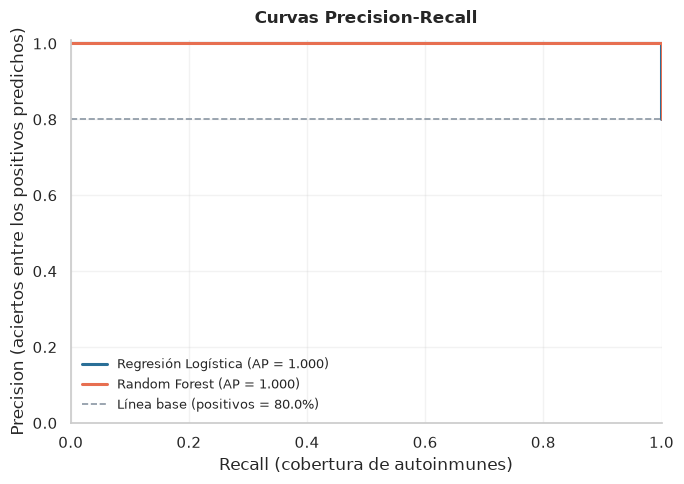

In [5]:
fig = precision_recall_curve_figure(results)
plt.show()


## Variables más influyentes

Los coeficientes estandarizados de la Regresión Logística permiten interpretar la dirección de las variables principales. El Random Forest coincide en PCR, VSG, ANA, hemoglobina y eritrocitos como variables de mayor importancia.


In [6]:
top_features(results["Regresión Logística"].model, top_n=10).round(3)


,variable,coeficiente
0,CRP,1.194
1,Hemoglobin,-0.944
2,ESR,0.934
3,RBC_Count,-0.917
4,MBL_Level,0.913
5,ANA,0.849
6,Hematocrit,-0.838
7,Anti-TPO,0.763
8,Anti-Sm,0.738
9,Rashes and skin lesions,0.706


## Conclusión

**Recomendación: Regresión Logística.** Es el modelo más simple e interpretable, no comete falsos negativos en este test y no pierde capacidad de discriminación frente al Random Forest. En un problema de triaje, un falso negativo es más costoso que un falso positivo: dejar pasar a un paciente con enfermedad autoinmune puede retrasar el diagnóstico, mientras que una derivación innecesaria implica una consulta o prueba adicional. Por eso la métrica prioritaria es el recall de la clase autoinmune, seguida de F1 para no degradar la precisión.

**Lectura crítica.** Un F1 y un AUC de 1,000 son una señal de alarma, no una garantía. El dataset es de una sola fuente, parece altamente separable y contiene variables que pueden estar codificando el diagnóstico. Antes de pensar en implementación clínica se necesita validación externa, calibración de probabilidades, auditoría de equidad por sexo y edad, y confirmar que todas las variables están disponibles en el momento del triaje. El modelo debe presentarse como apoyo a la decisión, nunca como diagnóstico automático.
